In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

from quantlab.data_loader import load_prices
from quantlab.returns import log_returns
from quantlab.diagnostics import fit_t, corr_by_period

r = log_returns(load_prices())
stocks = r.drop(columns="^GSPC")

In [2]:
tfit = fit_t(r)
tfit.round(3).sort_values("df")

,df,loc,scale
BAC,2.176,0.000,0.012
WFC,2.204,0.000,0.011
CSCO,2.302,0.001,0.012
JPM,2.307,0.001,0.012
ORCL,2.337,0.001,0.013
AMZN,2.441,0.001,0.016
GILD,2.580,0.001,0.014
^GSPC,2.637,0.001,0.007
MSFT,2.851,0.001,0.011
AMGN,2.853,0.000,0.012


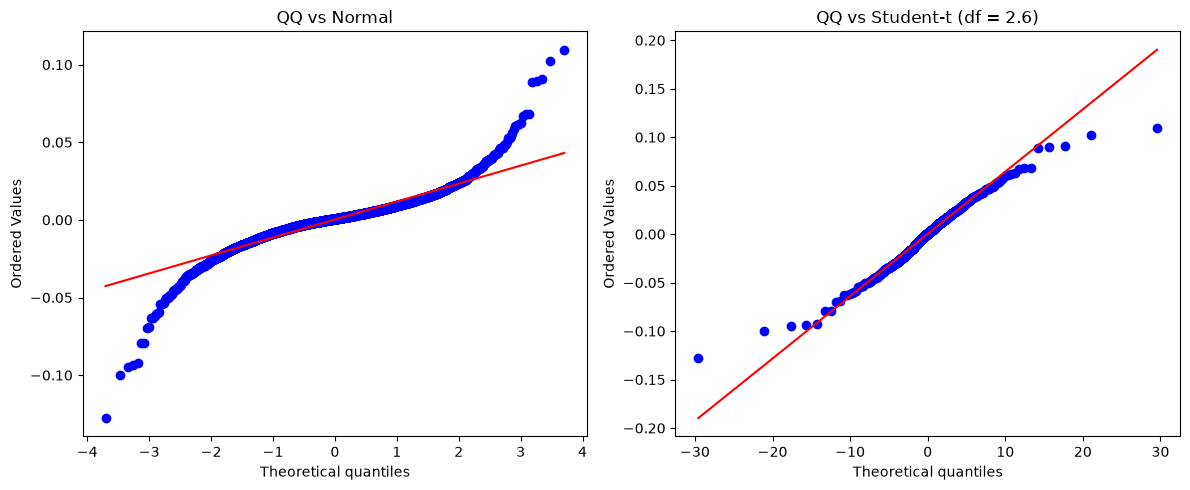

In [3]:
x = r["^GSPC"]
df_ = tfit.loc["^GSPC", "df"]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
stats.probplot(x, dist="norm", plot=ax[0])
ax[0].set_title("QQ vs Normal")
stats.probplot(x, dist=stats.t, sparams=(df_,), plot=ax[1])
ax[1].set_title(f"QQ vs Student-t (df = {df_:.1f})")
plt.tight_layout()
plt.show()

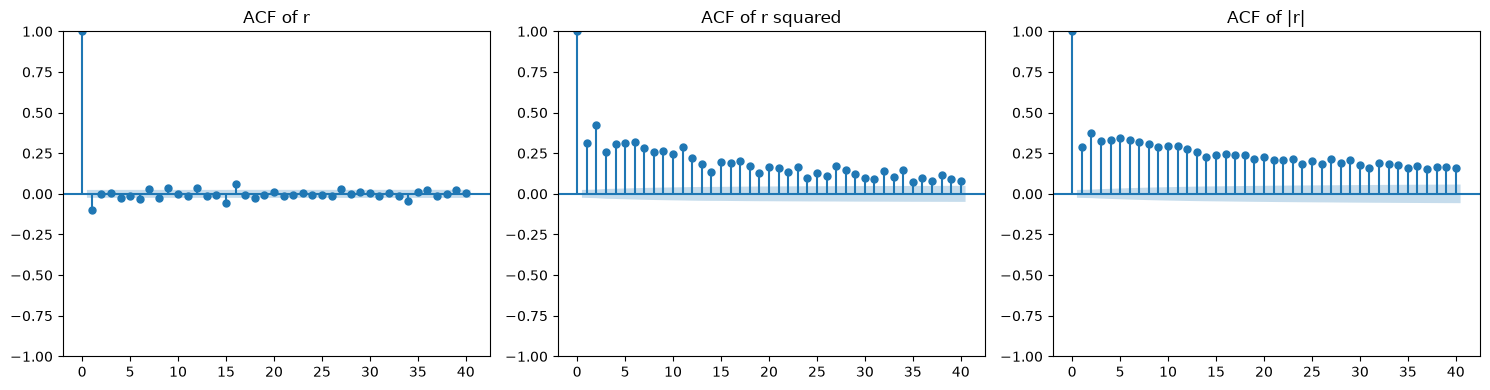

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot_acf(x, lags=40, ax=ax[0], title="ACF of r")
plot_acf(x**2, lags=40, ax=ax[1], title="ACF of r squared")
plot_acf(x.abs(), lags=40, ax=ax[2], title="ACF of |r|")
plt.tight_layout()
plt.show()

In [5]:
periods = {
    "2006-2007 (calm)": ("2006-01-01", "2007-06-30"),
    "Sep 2008-Mar 2009 (crisis)": ("2008-09-01", "2009-03-31"),
    "2019 (calm)": ("2019-01-01", "2019-12-31"),
    "Feb-Apr 2020 (crisis)": ("2020-02-15", "2020-04-30"),
    "full sample": ("2000-01-01", "2025-12-31"),
}
cc = corr_by_period(stocks, periods)
vol = pd.Series({k: stocks.loc[a:b].std().mean() * np.sqrt(252) for k, (a, b) in periods.items()})
pd.DataFrame({"avg_corr": cc, "avg_vol": vol}).round(3)

,avg_corr,avg_vol
2006-2007 (calm),0.262,0.209
Sep 2008-Mar 2009 (crisis),0.626,0.717
2019 (calm),0.299,0.204
Feb-Apr 2020 (crisis),0.719,0.795
full sample,0.341,0.315


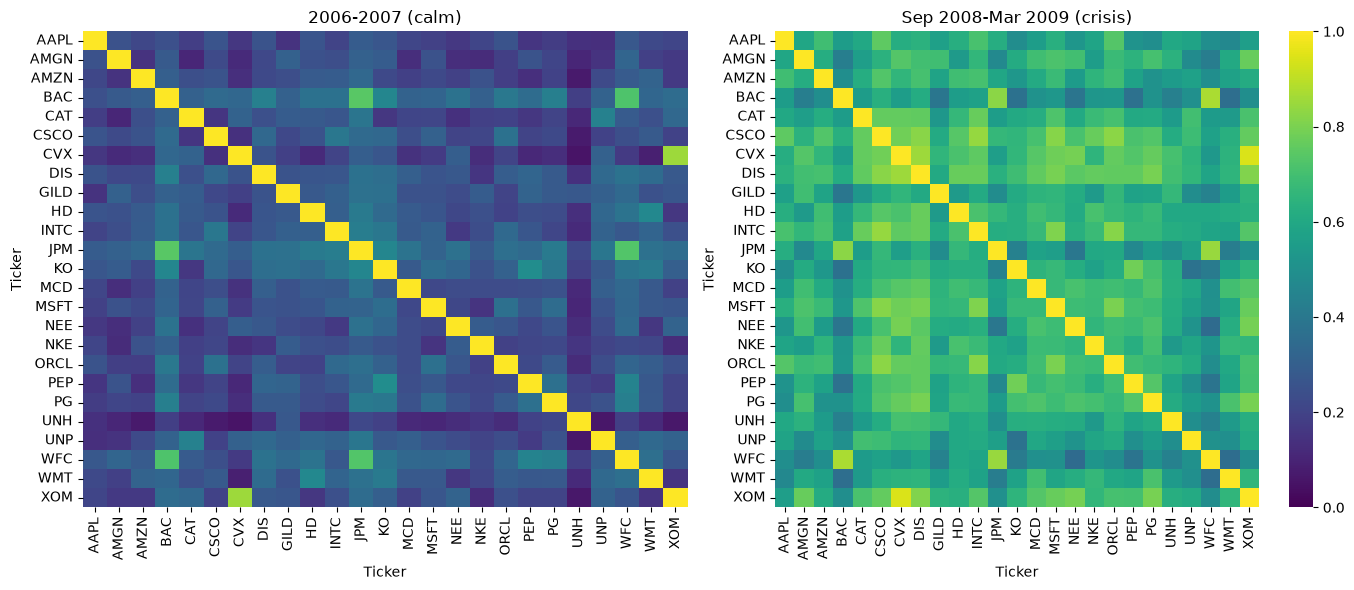

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, key in zip(ax, ["2006-2007 (calm)", "Sep 2008-Mar 2009 (crisis)"]):
    s, e = periods[key]
    sns.heatmap(stocks.loc[s:e].corr(), vmin=0, vmax=1, cmap="viridis", ax=a, cbar=a is ax[1])
    a.set_title(key)
plt.tight_layout()
plt.show()

## Conclusions (extra stylised facts)

**1. Student-t fit.** Every one of the 26 series fits a Student-t with between 2.2 and 3.6 degrees of freedom, far from the Normal (which corresponds to infinitely many). The heaviest tails are the banks: BAC 2.18, WFC 2.20, JPM 2.31, followed by CSCO 2.30, ORCL 2.34, AMZN 2.44 and GILD 2.58. The lightest are CAT 3.58, CVX 3.55, XOM 3.53 and UNP 3.43, but even these are below 4. The S&P 500 itself has 2.64, so diversifying across 500 stocks does not remove the heavy tails. A t distribution with 4 or fewer degrees of freedom has an infinite fourth moment, so the sample kurtosis measured earlier (for example AAPL at 114) is not a stable quantity but depends heavily on the few most extreme days in the sample. For BAC and WFC the fit is only just above 2, the point where even the variance stops existing, which is a warning that sample variances and covariances of these stocks are very unstable.

**2. The t fit is a better description, but not a full one.** In the QQ plot of the S&P 500, the Normal's points curl away from the line at both ends, while the Student-t fit follows the tails more closely. However, the t is fitted to the whole 26-year sample at once, so it mixes calm and turbulent regimes. Part of the "fat tails" it captures is probably the volatility clustering shown in notebook 01b: a single stable distribution is being fitted to a series whose scale changes over time. A static t, like a static Normal, cannot describe that.

**3. Volatility clustering is stronger in absolute returns.** The ACF of |r| (right-hand panel) shows the slow, long-lasting positive autocorrelation that characterises volatility clustering, while the ACF of r itself stays near zero. Absolute returns measure the size of moves without squaring away information, so they are less dominated by the few huge days and show the persistence more clearly than r squared.

**4. Correlations rise sharply in crises.** The average pairwise correlation across the 25 stocks is 0.26 in 2006-07 and 0.30 in 2019, but 0.63 in September 2008 to March 2009 and 0.72 in February to April 2020, more than doubling both times (about 2.4 times). The full-sample average is 0.34, close to the calm values, because crises make up a small share of days. Average volatility also jumped, from 21% and 20% to 72% and 80% a year. So a covariance matrix estimated over the whole sample understates how much stocks move together exactly when a portfolio most needs diversification. This is consistent with the backtest, where even the minimum-variance strategies had maximum drawdowns of 35% to 38%.

**5. Caveat: selection and sample size.** The crisis windows were chosen because volatility was extreme, and selecting high-volatility days raises measured correlation even if the underlying relationship stays fixed (the selection effect described by Forbes and Rigobon). Part of the rise from about 0.3 to about 0.7 may therefore be an artefact of how the windows were chosen, and this table cannot separate the two. The windows are also short: roughly 146 trading days for 2008-09 and about 53 for 2020, against 25 assets, so individual entries of those correlation matrices are noisy even though the average is a fairly stable summary.